In [53]:
from dotenv import load_dotenv
from pydantic import BaseModel
from typing import Annotated
from langchain_groq import ChatGroq
from langgraph.graph import START,END
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import InMemorySaver

In [54]:
load_dotenv()

True

In [55]:
class ChatState(BaseModel):
    messages:Annotated[list,add_messages]

In [56]:
llm = ChatGroq(
    model="qwen/qwen3.8-27b",
    temperature=0,
    max_tokens=None,
    reasoning_format="parsed",
    timeout=None,
    max_retries=2,
    streaming=True
    # other params...
)

In [57]:
def chat_node(state:ChatState) -> ChatState:
    response = llm.invoke(state.messages)
    state.messages = [response]
    return state

In [58]:
from langgraph.graph import StateGraph

graph = StateGraph(ChatState)

In [59]:
graph.add_node("Chatting_Node",chat_node)

In [60]:
graph.add_edge(START,"Chatting_Node")
graph.add_edge("Chatting_Node",END)

In [61]:
memory = InMemorySaver()

In [62]:
graph = graph.compile(checkpointer=memory)

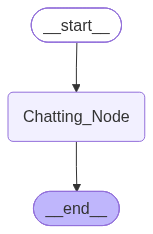

In [63]:
from IPython.display import Image
Image(graph.get_graph().draw_mermaid_png())

In [67]:
config = {"configurable":{"thread_id":"bot-101"}}
res = graph.invoke({"messages":[{"role":"user","content":"What is my name ?"}]},config)

In [68]:
print(res)

{'messages': [HumanMessage(content="Hello ! How r u ! I'm ABC", additional_kwargs={}, response_metadata={}, id='ab537ec3-cdab-496d-94e3-b34841f939db'), AIMessage(content="Hello ABC! I'm doing well, thank you for asking. How are you doing today?\n\nIs there anything specific I can help you with, or would you just like to chat?", additional_kwargs={}, response_metadata={'finish_reason': 'stop', 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_a1293f40b5', 'service_tier': 'on_demand', 'model_provider': 'groq'}, id='lc_run--01a12efa-ff5c-7753-85e3-320602f8e167', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 21, 'output_tokens': 39, 'total_tokens': 60}), HumanMessage(content='What is my name ?', additional_kwargs={}, response_metadata={}, id='71359103-ff99-4161-b382-6cdeb5f556aa'), AIMessage(content='Your name is ABC.', additional_kwargs={}, response_metadata={'finish_reason': 'stop', 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_a1293f40b5',

In [69]:
print(res["messages"][-1].content)

Your name is ABC.
